In [3]:
import site, sys
print(sys.executable)
print(site.getusersitepackages())

c:\Program Files\Python313\python.exe
D:\Python\userbase\Python313\site-packages


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split,cross_val_score,KFold,GridSearchCV,learning_curve
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler,FunctionTransformer
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.metrics import r2_score,mean_squared_error,root_mean_squared_error
import joblib
import sklearn

RANDOM_STATE=42
cvfolds=KFold(5,shuffle=True,random_state=RANDOM_STATE)
max_iter=100000

In [5]:
df=pd.read_csv('Advertising.csv')
df.head()
df.info()
df.duplicated()
df.columns=df.columns.str.lower()
df.columns


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


Index(['tv', 'radio', 'newspaper', 'sales'], dtype='object')

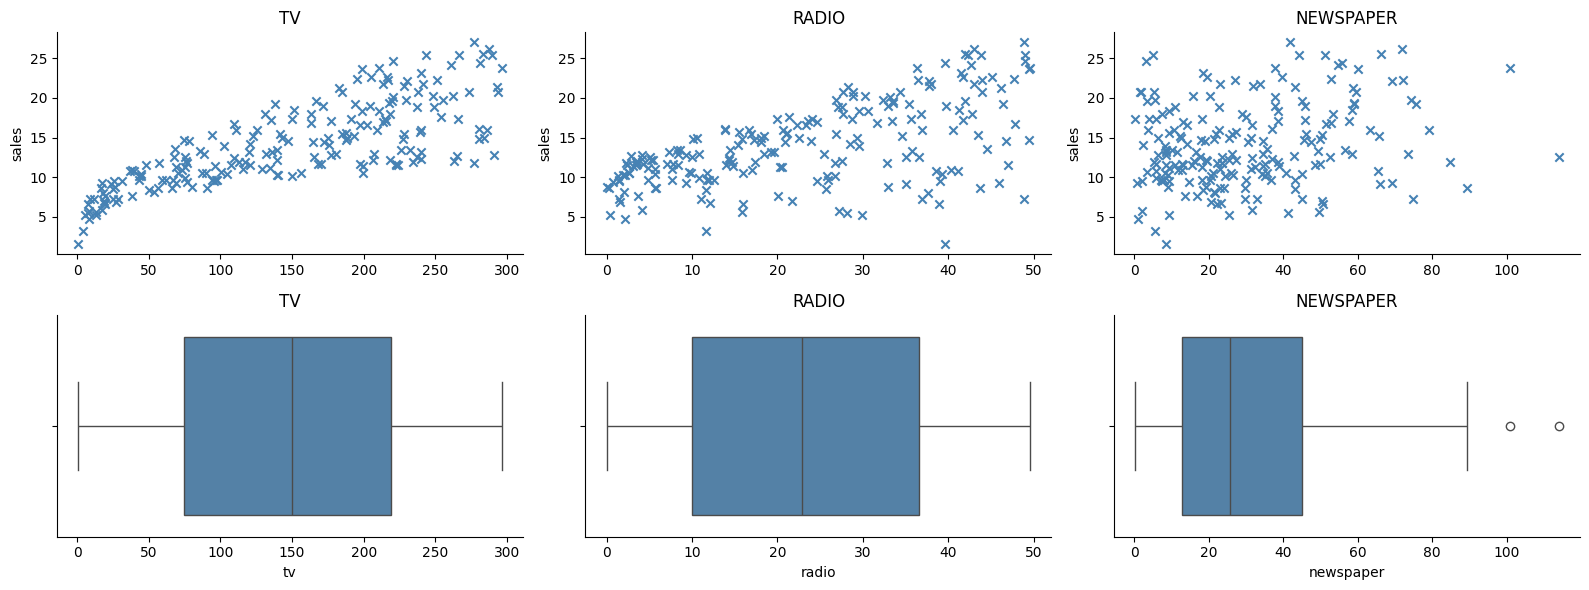

In [6]:
columns=['tv','radio','newspaper']
fig,axes=plt.subplots(2,3,figsize=(16,6))

for i, col in enumerate(columns):
    axes[0,i].scatter(df[col],df['sales'],marker='x',c='steelblue')
    axes[0,i].set_ylabel('sales')
    axes[0,i].set_title(col.upper())

    sns.boxplot(x=df[col],ax=axes[1,i],color='steelblue')
    axes[1,i].set_title(col.upper())
    

for ax in axes.ravel():
    ax.spines[['top','right']].set_visible(False)

plt.tight_layout()



Obsverations:
tv has curvature and flattens out around 300 . diminishing returns pattern. concave transformation may help
radio is linear 
newspaper has outliers,marginal but not influenctial as corresponding sales are normal 

D:\Python\userbase\Python313\site-packages\seaborn\categorical.py:700: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  artists = ax.bxp(**boxplot_kws)


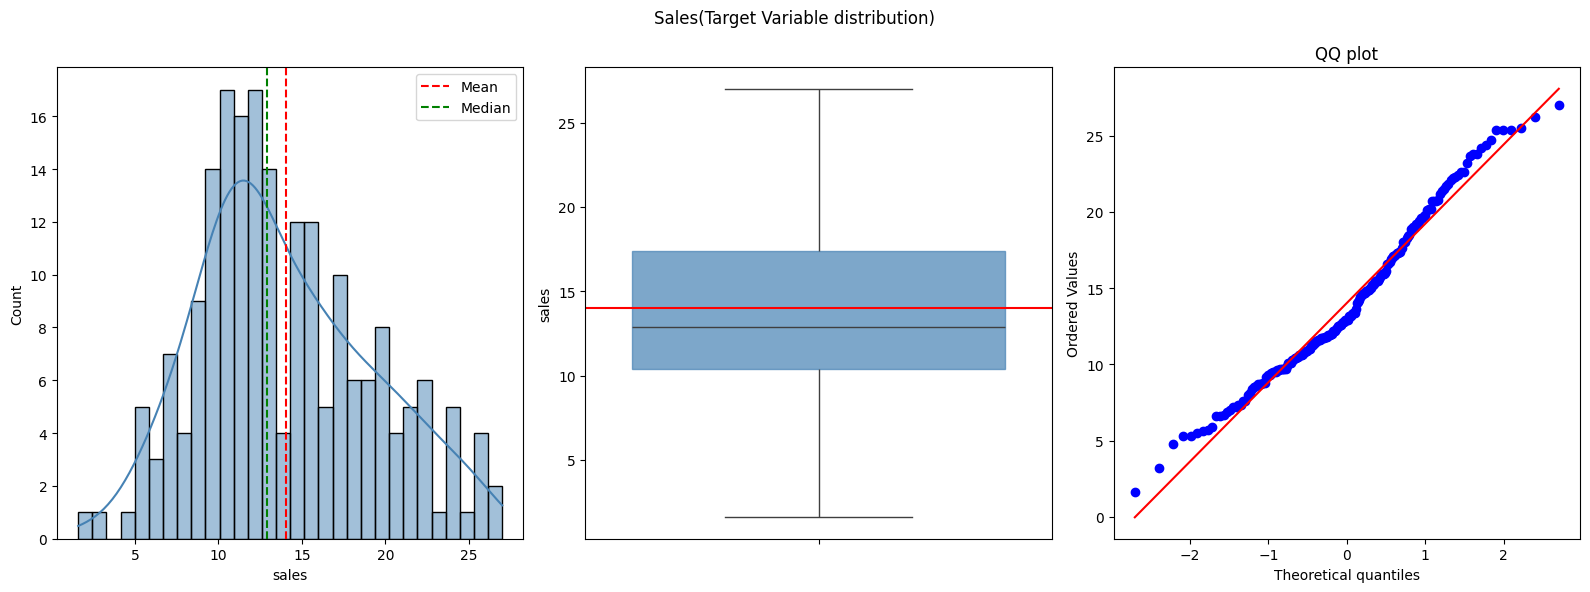

In [7]:
fig,axes=plt.subplots(1,3,figsize=(16,6))
fig.suptitle('Sales(Target Variable distribution)')
sns.histplot(x=df['sales'],bins=30,kde=True,edgecolor='black',linewidth=1,color='steelblue',ax=axes[0])
axes[0].axvline(df['sales'].mean(),ls='--',c='r',label='Mean')
axes[0].axvline(df['sales'].median(),ls='--',c='g',label='Median')
axes[0].legend()

sns.boxplot(y=df['sales'],ax=axes[1],patch_artist=True,boxprops=dict(color='steelblue',alpha=0.7))
axes[1].axhline(df['sales'].mean(),c='r',ls='-',label='mean')

_=stats.probplot(df['sales'],dist='norm',plot=axes[2])
axes[2].set_title('QQ plot')


plt.tight_layout()





obsverations:
almost univariate normal with mild right skew. 
no outliers. 

Text(0.5, 1.0, 'QQ plot of log sales')

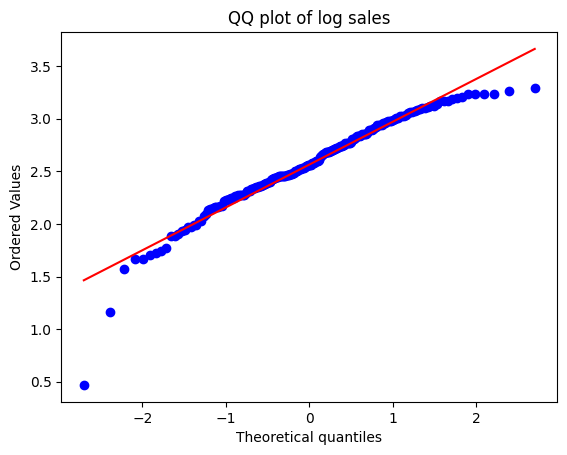

In [8]:
#checking if log transformation on target helps
fig,axes=plt.subplots()
_=stats.probplot(np.log(df['sales']),dist='norm',plot=axes)
axes.set_title('QQ plot of log sales')

<Axes: >

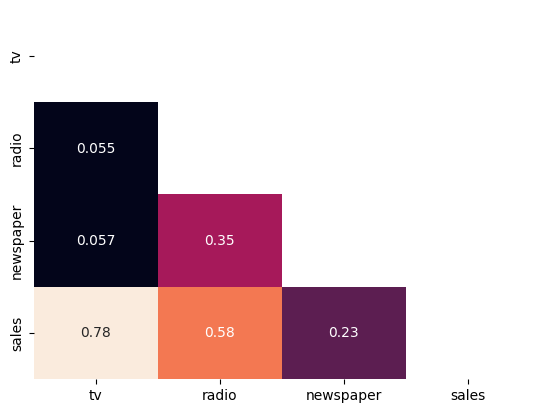

In [9]:
mask=np.triu(np.ones_like(df.corr()))
sns.heatmap(df.corr(),mask=mask,annot=True,cbar=False)

no major correlation 

In [10]:
X=df.drop('sales',axis=1)
y=df['sales']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

In [12]:
X_c=sm.add_constant(X_train)
features=X_c.columns
values=[variance_inflation_factor(X_c.values,i) for i  in range(X_c.shape[1])]
vif_df=pd.DataFrame({'feature':features,
                     'values':values}).sort_values('values',key=abs)
vif_df[vif_df['feature']!='const']

,feature,values
1,tv,1.002915
3,newspaper,1.177309
2,radio,1.180305


obs:
all values <5  so multicollinearity is not an issue

In [13]:
def flag_iqr(data):
    Q1,Q3=data.quantile([0.25,0.75])
    IQR=Q3-Q1
    return (data < Q1 - 1.5*IQR) | (data> Q3 + 1.5*IQR)

outlier_flag=X_train.apply(flag_iqr)
outlier_flag.sum()

tv           0
radio        0
newspaper    1
dtype: int64

In [14]:
X_train[outlier_flag.any(axis=1)]

,tv,radio,newspaper
101,296.4,36.3,100.9


In [15]:
pd.concat([X_train,y_train],axis=1).apply(flag_iqr).sum()

tv           0
radio        0
newspaper    1
sales        0
dtype: int64

In [16]:
#dummy basline
dummy_model=DummyRegressor(strategy='mean')
dummy_score=cross_val_score(dummy_model,X_train,y_train,cv=cvfolds,scoring='neg_mean_squared_error')
dummy_mse_cv=-dummy_score.mean()
print(f'Dummy MSE CV :{dummy_mse_cv:.3f}')


Dummy MSE CV :26.684


In [17]:
#basline model
baseline_model=LinearRegression(fit_intercept=True)

baseline_score_cv=cross_val_score(baseline_model,X_train,y_train,cv=cvfolds,scoring='neg_mean_squared_error')
r2_score_cv=cross_val_score(baseline_model,X_train,y_train,scoring='r2',cv=cvfolds)

baseline_mse_cv=-baseline_score_cv.mean()
rmse=np.sqrt(-baseline_score_cv)
rmse_insample=np.sqrt(baseline_mse_cv)
r2_cv=r2_score_cv.mean()

print(f'Baseline MSE CV: {baseline_mse_cv:.2f}')
print(f'Improvement over dummy: {dummy_mse_cv / baseline_mse_cv :.1f}x')
print(f'baseline rmse per fold {rmse.mean():.3f} ± {rmse.std():.3f}') #per fold 
print(f'baseline rmse {rmse_insample:.3f} ') #in sample
print(f'basline R2 CV perfold:{r2_cv:.3f} ± {r2_score_cv.std():.3f}') #per fold r2 and then average
print(f'baseline R2 {1- baseline_mse_cv / dummy_mse_cv:.3f}') # model in sample r2
print(f'target mean {y_train.mean():.3f} target std {y_train.std():.3f}')

Baseline MSE CV: 2.88
Improvement over dummy: 9.3x
baseline rmse per fold 1.676 ± 0.266
baseline rmse 1.697 
basline R2 CV perfold:0.870 ± 0.072
baseline R2 0.892
target mean 14.100 target std 5.109


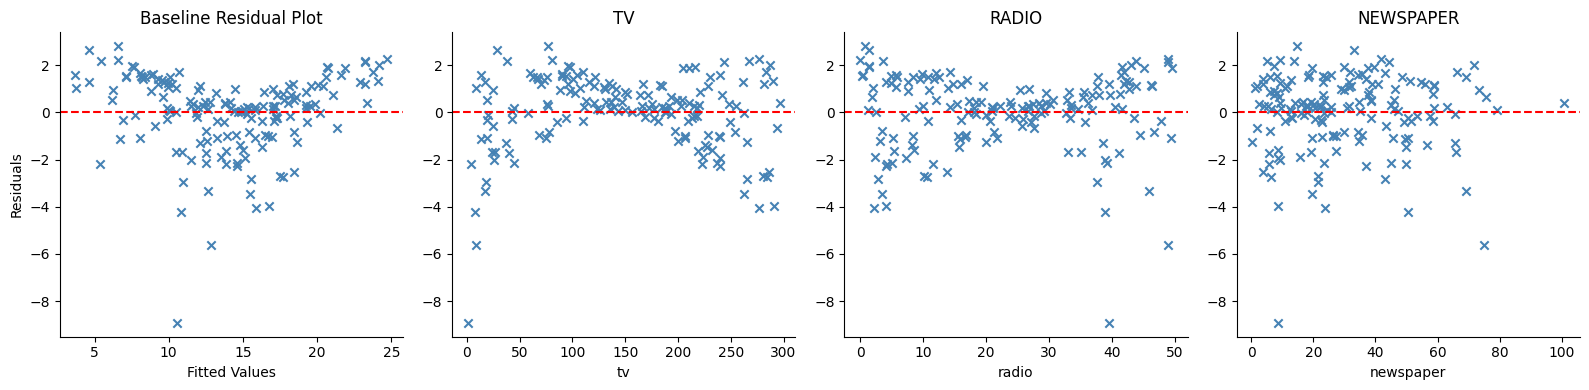

In [18]:
baseline_model.fit(X_train,y_train)
baseline_pred=baseline_model.predict(X_train)
baseline_resd=y_train-baseline_pred

fig, axes= plt.subplots(1,4,figsize=(16,4))
axes[0].scatter(baseline_pred,baseline_resd,marker='x',color='steelblue')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Baseline Residual Plot')
axes[0].axhline(y=0,c='r',ls='--')

for ax , col in zip(axes[1:],['tv','radio','newspaper']):
    ax.scatter(X_train[col],baseline_resd,marker='x',color='steelblue')
    ax.axhline(y=0,c='r',ls='--')
    ax.set_xlabel(col)
    ax.set_title(col.upper())

for ax in axes:
    ax.spines[['top','right']].set_visible(False)
plt.tight_layout()


obs:
there is curve in residual plot, meaning relationship is not completly linear
for tv there is donward u , coupled together with curved scatter , we for sure need non linear terms like tv squared . (all are above y=0 )
for radio , the scatter was straight line . but the residual shows upward u , so there needs an interaction term for radio . maybe tv*radio 
for newspaper , there is just random cloud , both in scatter or residual . this may not even matter . 

(np.float64(5.2454321027129325), np.float64(-1.6425561129054371))

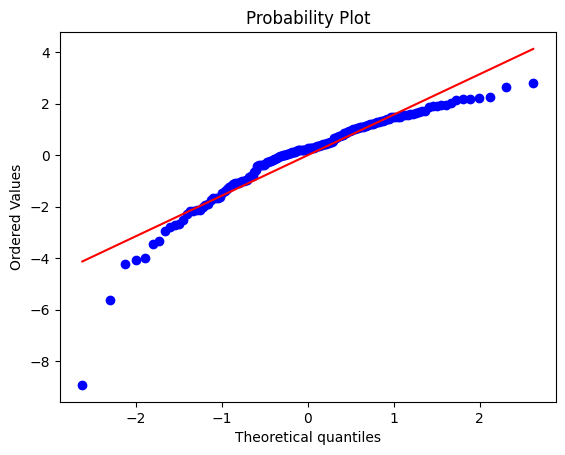

In [19]:
fig,axes=plt.subplots()
_=stats.probplot(baseline_resd,dist='norm',plot=axes)
baseline_resd.kurt(), baseline_resd.skew()


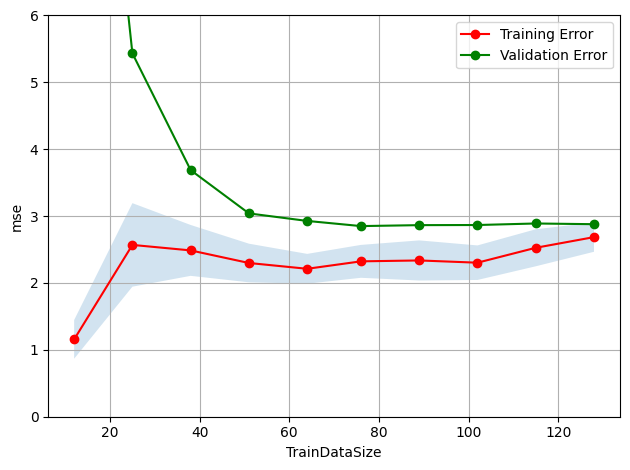

In [20]:
train_size,train_scores,test_scores=learning_curve(baseline_model,X_train,y_train,scoring='neg_mean_squared_error',cv=cvfolds,train_sizes=np.linspace(0.1,1,10),random_state=RANDOM_STATE)
train_mean,train_std=-train_scores.mean(axis=1),train_scores.std(axis=1)
plt.figure()
plt.plot(train_size,train_mean,'o-',c='r',label='Training Error')
plt.plot(train_size,-test_scores.mean(axis=1),'o-',c='g',label='Validation Error')
plt.fill_between(train_size,train_mean-train_std,train_mean+train_std,alpha=0.2)
plt.xlabel('TrainDataSize')
plt.ylabel('mse');plt.grid(True)
plt.legend(loc='best');plt.ylim(0,6)
plt.tight_layout()

both train error and val error is high , another confirmation of high bias  and that we need to add features. as conifrmed from residual plot , residual plot of tv  radio , scatter of tv . 

In [21]:
#polynomial and reg
alphas=np.logspace(-3,3,30)
degree=np.arange(1,5)

def tune_hyperparamters(model):
    p=Pipeline([('poly',PolynomialFeatures(include_bias=False)),('scalar',StandardScaler()),('model',model)])

    if isinstance(model,(Ridge,Lasso)):
        params_gird={'poly__degree':degree,
                     'model__alpha':alphas}
    else:
        params_gird={'poly__degree':degree,
        'model__alpha':alphas,
        'model__l1_ratio':[.1,.3,.5,.7,.9,.95,1]}
    g=GridSearchCV(p,param_grid=params_gird,scoring='neg_mean_squared_error',cv=cvfolds,n_jobs=-1)
    g.fit(X_train,y_train)
    return g

lasso_g=tune_hyperparamters(Lasso(max_iter=max_iter))
ridge_g=tune_hyperparamters(Ridge())
elasticNet_g=tune_hyperparamters(ElasticNet(max_iter=max_iter))

lasso_best_params,lasso_best_score=lasso_g.best_params_,-lasso_g.best_score_
ridge_best_params,ridge_best_score=ridge_g.best_params_,-ridge_g.best_score_
elasticnet_best_params,elasticnet_best_score=elasticNet_g.best_params_,-elasticNet_g.best_score_

print(f'lasso : params {lasso_best_params}  score {lasso_best_score:.3f}')
print(f'ridge : params {ridge_best_params}  score {ridge_best_score:.3f}')
print(f'elasticnet : params {elasticnet_best_params}  score {elasticnet_best_score:.3f}')

lasso : params {'model__alpha': np.float64(0.0016102620275609393), 'poly__degree': np.int64(3)}  score 0.414
ridge : params {'model__alpha': np.float64(0.006723357536499335), 'poly__degree': np.int64(4)}  score 0.498
elasticnet : params {'model__alpha': np.float64(0.0016102620275609393), 'model__l1_ratio': 1, 'poly__degree': np.int64(3)}  score 0.414


In [22]:
final_pipeline=lasso_g.best_estimator_

In [23]:
#lets see coffiecient values
features=final_pipeline.named_steps['poly'].get_feature_names_out(input_features=X_train.columns)
values=final_pipeline.named_steps['model'].coef_
feature_values=pd.DataFrame({
    'features':features,
    'values' :values
}).sort_values('values',key=abs,ascending=False)
feature_values


,features,values
3,tv^2,-9.192258
0,tv,6.894421
9,tv^3,4.119615
4,tv radio,4.087758
5,tv newspaper,-0.758825
10,tv^2 radio,-0.590778
11,tv^2 newspaper,0.498746
2,newspaper,0.387912
1,radio,0.338803
12,tv radio^2,0.243463


In [24]:
xp=final_pipeline[:-1].transform(X_train)
xp_with_const=np.column_stack([np.ones(len(xp)),xp])
print(np.linalg.cond(xp_with_const))

109.15868354930282


In [25]:
xp.shape

(160, 19)

obs: for tv they are forming saturating shape through cancellation as tv , tv^2 and tv^3 are very large compared to rest and have opposong signs, modest fitting curve   .
cubic in tv lives in a 4-dimensional function space: the span of {1, tv, tv², tv³}. Any cubic is a point in that space. The monomial basis is one set of axes for it. But those axes are nearly parallel over our data range — tv and tv² both increase monotonically across 0–300, so as vectors of length n (evaluated at our data points) they point in almost the same direction.Fitting in a near-parallel basis is the whole disease. To express a point in a space using nearly-parallel axes, we need large coefficients that cancel. That's mechanically what we;re seeing: +6.89, −9.19, +4.12. The function is modest; the coordinates are extreme, because the coordinate system is bad.Orthogonal polynomials are a different basis for the same space. Construct P₀, P₁, P₂, P₃ such that they're mutually orthogonal as evaluated on your data — i.e. the columns of the design matrix are perpendicular. Now the axes are at right angles. Each coefficient is the projection of y onto one axis, computed independently of the others.( othogonal projection ,lets leave that for later).

seems higly collinear (can be confirmed with vif , condition number).cv score doesnt show this it measure interpolation , but with tv^3 the predicted sales accelrate upward past tv 300. 
with interior curvature negative there is likely a downward bend near the bondary too.so extrapolation failure .A cubic has exactly one inflection point, so the sign pattern is: the curve bends one way, crosses the inflection, bends the other. With −9.19 on tv² and +4.12 on tv³, second derivative is 2(−9.19) + 6(4.12)·tv, which is negative for small tv and turns positive at tv ≈ 0.74 in scaled units. So it's concave (saturating) at low tv and convex (accelerating) at high tv

if we bootstrape resample and refit then the predictions will not change much but the coefficients will as they are not individually identified, their combination is. hence no interpretability . (tv)

polynomial genuinely fits shown by 0.414 mse  , but the issue is with the generalisation and interpretability .

sparsity pattern in presence of colinearity is unstable

lets check if we actually need degree 3 by plotting cv results and verifying if this sits in flat region or not. max alpha within 1 SE of mse and in that region we choose the smallest degree

In [26]:
cv_results=pd.DataFrame(lasso_g.cv_results_)
cv_results.columns

Index(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time',
       'param_model__alpha', 'param_poly__degree', 'params',
       'split0_test_score', 'split1_test_score', 'split2_test_score',
       'split3_test_score', 'split4_test_score', 'mean_test_score',
       'std_test_score', 'rank_test_score'],
      dtype='object')

best min mse degree :3  alpha 0.0016  mse 0.414
threshold 0.590
1SE  degree :2  alpha 0.0281  mse 0.547


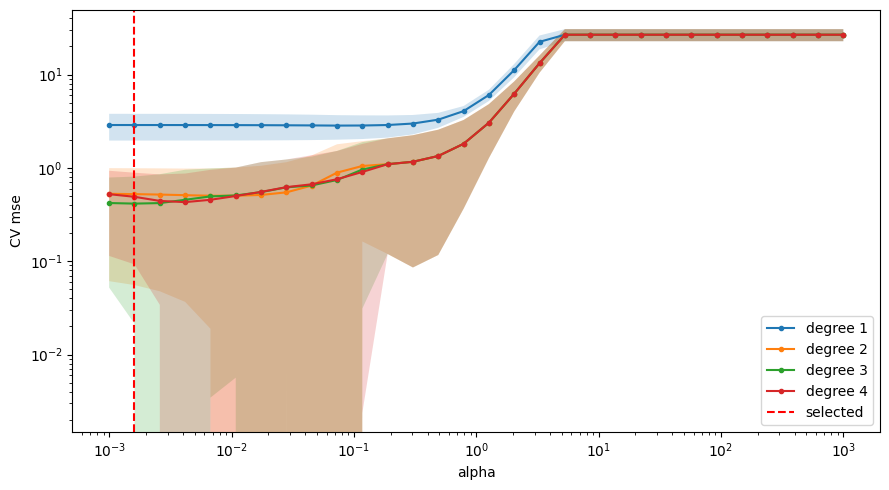

In [27]:
cv_results['mse']=-cv_results['mean_test_score']
cv_results['std']=cv_results['std_test_score']
cv_results['se']=cv_results['std_test_score']/np.sqrt(5)

fig, axes= plt.subplots(figsize=(9,5))

for d in sorted(cv_results['param_poly__degree'].unique()):
    sub=cv_results[cv_results['param_poly__degree']==d].sort_values('param_model__alpha')
    axes.plot(sub['param_model__alpha'],sub['mse'],marker='.',label=f'degree {d}')
    axes.fill_between(sub['param_model__alpha'],sub['mse']-sub['std'],sub['mse']+sub['std'],alpha=0.2)

axes.set_xlabel('alpha');axes.set_ylabel('CV mse')
axes.set_xscale('log');axes.set_yscale('log')
axes.axvline(lasso_best_params['model__alpha'],c='r',ls='--',label='selected')
axes.legend(loc='best');plt.tight_layout()

best=cv_results.loc[cv_results['mse'].idxmin()]
thresh=best['mse']+best['se']
within=cv_results[cv_results['mse']<=thresh]
pick_1se=within.loc[within['param_model__alpha'].idxmax()]

print(f'best min mse degree :{best['param_poly__degree']}  alpha {best['param_model__alpha']:.4f}  mse {best['mse']:.3f}')
print(f'threshold {thresh:.3f}')
print(f'1SE  degree :{pick_1se['param_poly__degree']}  alpha {pick_1se['param_model__alpha']:.4f}  mse {pick_1se['mse']:.3f}')



In [28]:
best_alpha=pick_1se['param_model__alpha']
best_degree=pick_1se['param_poly__degree']

final_pipeline_1SE=Pipeline([('poly',PolynomialFeatures(degree=best_degree,include_bias=False)),('scalar',StandardScaler()),('model',Lasso(alpha=best_alpha,max_iter=max_iter))])

final_pipeline_1SE.fit(X_train,y_train)

,steps,"[('poly', ...), ('scalar', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,degree,np.int64(2)
,interaction_only,False
,include_bias,False
,order,'C'
,copy,True
,with_mean,True
,with_std,True


In [29]:
score_cv_1SE =cross_val_score(final_pipeline_1SE,X_train,y_train,cv=cvfolds,scoring='neg_mean_squared_error')
r2_score_1SE_cv=cross_val_score(final_pipeline_1SE,X_train,y_train,scoring='r2',cv=cvfolds)

mse_1se=-score_cv_1SE.mean()
rmse=np.sqrt(-score_cv_1SE)
rmse_insample_1SE=np.sqrt(mse_1se)
r2_s1SE_cv=r2_score_1SE_cv.mean()

print(f'Baseline MSE CV: {baseline_mse_cv:.2f}')
print(f'1se MSE CV: {mse_1se:.2f}')
print(f'Improvement over baseline: { baseline_mse_cv/mse_1se  :.1f}x')
print(f'Improvement over dummy: { dummy_mse_cv/mse_1se  :.1f}x')
print(f'1se R2 CV perfold:{r2_score_1SE_cv.mean():.3f} ± {r2_score_1SE_cv.std():.3f}') #per fold r2 and then average
print(f'1se rmse per fold {rmse.mean():.3f} ± {rmse.std():.3f}') #per fold 
print(f'1se rmse {rmse_insample_1SE:.3f} ') #in sample
print(f'1se R2 {1- mse_1se / dummy_mse_cv:.3f}') # model in sample r2
print(f'target mean {y_train.mean():.3f} target std {y_train.std():.3f}')

Baseline MSE CV: 2.88
1se MSE CV: 0.55
Improvement over baseline: 5.3x
Improvement over dummy: 48.8x
1se R2 CV perfold:0.978 ± 0.022
1se rmse per fold 0.660 ± 0.334
1se rmse 0.739 
1se R2 0.980
target mean 14.100 target std 5.109


Baseline MSE CV: 2.88
Improvement over dummy: 9.3x
basline R2 CV perfold:0.870 ± 0.072
baseline rmse per fold 1.676 ± 0.266
baseline rmse 1.697 
baseline R2 0.892
target mean 14.100 target std 5.109

In [30]:

print(np.linalg.cond(final_pipeline_1SE[:-1].transform(X_train)))
pd.Series(final_pipeline_1SE[-1].coef_,index=final_pipeline_1SE[:-1].get_feature_names_out()).sort_values(key=abs, ascending=False)

13.506074672946049


tv radio           3.557894
tv                 3.476253
tv^2              -1.969004
radio              0.390394
radio newspaper    0.079276
radio^2            0.028438
newspaper          0.000000
tv newspaper      -0.000000
newspaper^2        0.000000
dtype: float64

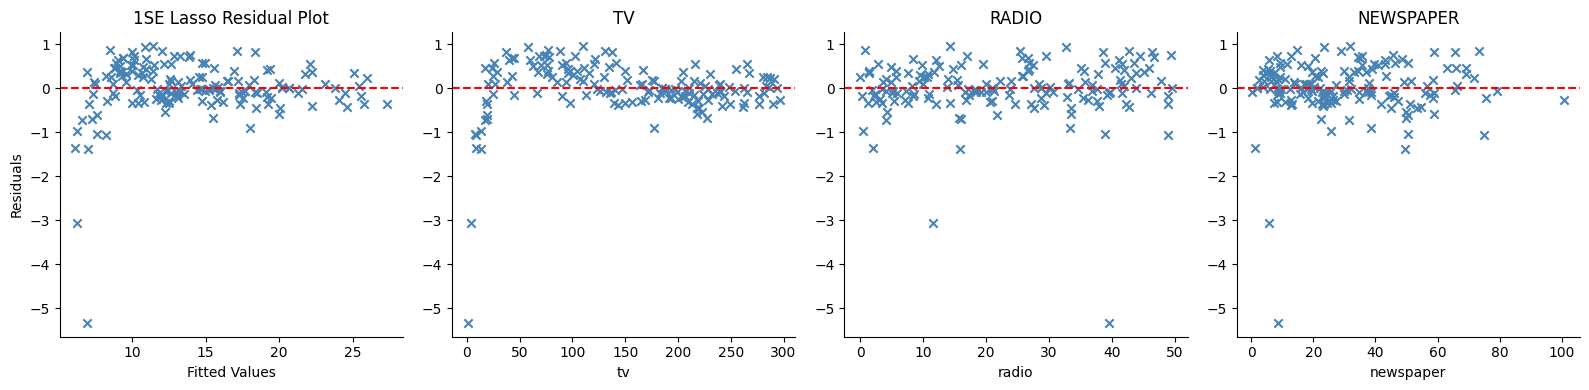

In [31]:
pred_1se=final_pipeline_1SE.predict(X_train)
resd_1se=y_train-pred_1se

fig, axes= plt.subplots(1,4,figsize=(16,4))
axes[0].scatter(pred_1se,resd_1se,marker='x',color='steelblue')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('1SE Lasso Residual Plot')
axes[0].axhline(y=0,c='r',ls='--')

for ax , col in zip(axes[1:],['tv','radio','newspaper']):
    ax.scatter(X_train[col],resd_1se,marker='x',color='steelblue')
    ax.axhline(y=0,c='r',ls='--')
    ax.set_xlabel(col)
    ax.set_title(col.upper())

for ax in axes:
    ax.spines[['top','right']].set_visible(False)
plt.tight_layout()


In [32]:
Xp=final_pipeline_1SE[:-1].transform(X_train)
names=final_pipeline_1SE[:-1].get_feature_names_out()
Xp=pd.DataFrame(Xp,columns=names,index=X_train.index)
keep=['tv','tv radio','tv^2','radio']
Xs=sm.add_constant(Xp[keep])

m=sm.OLS(y_train,Xs).fit(cov_type='HC3')
print(m.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.985
Model:                            OLS   Adj. R-squared:                  0.985
Method:                 Least Squares   F-statistic:                     4887.
Date:                Wed, 07 Oct 2026   Prob (F-statistic):          6.57e-162
Time:                        18:11:51   Log-Likelihood:                -150.43
No. Observations:                 160   AIC:                             310.9
Df Residuals:                     155   BIC:                             326.2
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         14.1000      0.052    270.578      0.0

exog: design matrix, endog: target variable

In [33]:
infl = m.get_influence()
sf = infl.summary_frame()
sf.columns
print(sf[['cooks_d', 'hat_diag', 'student_resid']]
      .sort_values('cooks_d', ascending=False).head(8))
n, p = m.model.exog.shape
print('threshold 4/n:', 4/n)

      cooks_d  hat_diag  student_resid
130  1.281049  0.085086     -11.097399
155  0.246951  0.065121      -4.459386
8    0.036048  0.090582      -1.348755
2    0.035924  0.083992       1.403999
35   0.028030  0.100426       1.121378
131  0.024610  0.064936       1.334481
183  0.023457  0.079953       1.163070
134  0.023372  0.039602       1.693555
threshold 4/n: 0.025


Cook's D > 1 is the classical "this single row is moving the entire fit".

for 130 , leverage is not that large , its the residual which is pulling the fit .
for 155 as well its 0.247
and then it drops by orders of magnitude. these 2 rows needs to be checked


we dont have 101 becuase , it got zeroed out by lasso (univariate feature screening and residual/influence diagnostics answer different questions, and neither substitutes for the other.)

In [34]:
lm, lm_p, f, f_p = het_breuschpagan(m.resid, m.model.exog)
print(f"Breusch-Pagan p = {lm_p:.4f}")

Breusch-Pagan p = 0.0010


Breusch-Pagan answers does the error variance depends on the predictors. if p<0.05 we reject the constant variance of errors.

In [35]:
print(pd.concat([X_train, y_train], axis=1).loc[[130, 155]])
print(pd.concat([X_train, y_train], axis=1).describe())

      tv  radio  newspaper  sales
130  0.7   39.6        8.7    1.6
155  4.1   11.6        5.7    3.2
               tv       radio   newspaper       sales
count  160.000000  160.000000  160.000000  160.000000
mean   150.019375   22.875625   29.945625   14.100000
std     84.418857   14.805216   20.336449    5.108754
min      0.700000    0.000000    0.300000    1.600000
25%     77.750000    9.825000   12.875000   10.475000
50%    150.650000   21.200000   25.600000   13.200000
75%    218.825000   36.425000   44.500000   17.325000
max    296.400000   49.600000  100.900000   27.000000


In [36]:
mask = ~y_train.index.isin([130, 155])
ols_clean = sm.OLS(y_train[mask], Xs.loc[mask]).fit(cov_type='HC3')

print(pd.DataFrame({'full': m.params, 'clean': ols_clean.params,
                    'pct_change': 100*(ols_clean.params - m.params)/m.params.abs()}))
print('BP p full :', het_breuschpagan(m.resid, m.model.exog)[1])
print('BP p clean:', het_breuschpagan(ols_clean.resid, ols_clean.model.exog)[1])

               full      clean  pct_change
const     14.100000  14.153098    0.376584
tv         4.334536   3.882972  -10.417818
tv radio   3.525741   3.414826   -3.145873
tv^2      -2.809896  -2.371051   15.617841
radio      0.542292   0.636975   17.459935
BP p full : 0.000988369357108366
BP p clean: 3.888979332131668e-06


bp moved in other direction . so the non constant variance  of residuals seems like a  feature of the data itself not driven by outliers. 
we can try log on target variable and refit to see if it helps. or maybe polynomial is not right fit lets check with targeted model



the scatter plot and residual plot showed concave shape for tv , and interaction for radio . so i am gonna try a targeted model with log tv , radio and radio^tv

In [37]:

# order robust
def targeted_features(data):
    df = pd.DataFrame(data) if not isinstance(data, pd.DataFrame) else data
    tv, radio = df['tv'].values, df['radio'].values
    return np.column_stack([np.log(tv+1),radio,tv*radio])

def name(transformer,input_features):
    return np.array(['log_tv','radio','radio_x_tv'])

targeted_pipe=Pipeline([('feature',FunctionTransformer(targeted_features,validate=False,feature_names_out=name)),('model',LinearRegression())])
targeted_pipe.fit(X_train,y_train)
scores = cross_val_score(targeted_pipe, X_train, y_train, scoring='neg_mean_squared_error', cv=cvfolds)
targeted_score_cv=cross_val_score(targeted_pipe,X_train,y_train,scoring='r2',cv=cvfolds)


In [38]:
r2_score_1SE_cv=cross_val_score(final_pipeline_1SE,X_train,y_train,scoring='r2',cv=cvfolds)

mse_targeted=-scores.mean()
rmse=np.sqrt(-scores)
rmse_insample_targeted=np.sqrt(mse_targeted)
r2_Targeted_cv=targeted_score_cv.mean()

print(f'Baseline MSE CV: {baseline_mse_cv:.2f}')
print(f'1se MSE CV: {mse_1se:.2f}')
print(f'Targeted MSE CV: {mse_targeted:.2f}')
print(f'Improvement over baseline: { baseline_mse_cv/mse_targeted  :.1f}x')
print(f'Improvement over dummy: { dummy_mse_cv/mse_targeted  :.1f}x')
print(f'Targeted R2 CV perfold:{targeted_score_cv.mean():.3f} ± {targeted_score_cv.std():.3f}') #per fold r2 and then average
print(f'targeted rmse per fold {rmse.mean():.3f} ± {rmse.std():.3f}') #per fold 
print(f'targeted rmse {rmse_insample_targeted:.3f} ') #in sample
print(f'targeted R2 {1- mse_targeted / dummy_mse_cv:.3f}') # model in sample r2
print(f'target mean {y_train.mean():.3f} target std {y_train.std():.3f}')

Baseline MSE CV: 2.88
1se MSE CV: 0.55
Targeted MSE CV: 0.10
Improvement over baseline: 29.3x
Improvement over dummy: 271.2x
Targeted R2 CV perfold:0.996 ± 0.001
targeted rmse per fold 0.312 ± 0.029
targeted rmse 0.314 
targeted R2 0.996
target mean 14.100 target std 5.109


Baseline MSE CV: 2.88
1se MSE CV: 0.55
Improvement over baseline: 5.3x
Improvement over dummy: 48.8x
1se R2 CV perfold:0.978 ± 0.022
1se rmse per fold 0.660 ± 0.334
1se rmse 0.739 
1se R2 0.980
target mean 14.100 target std 5.109

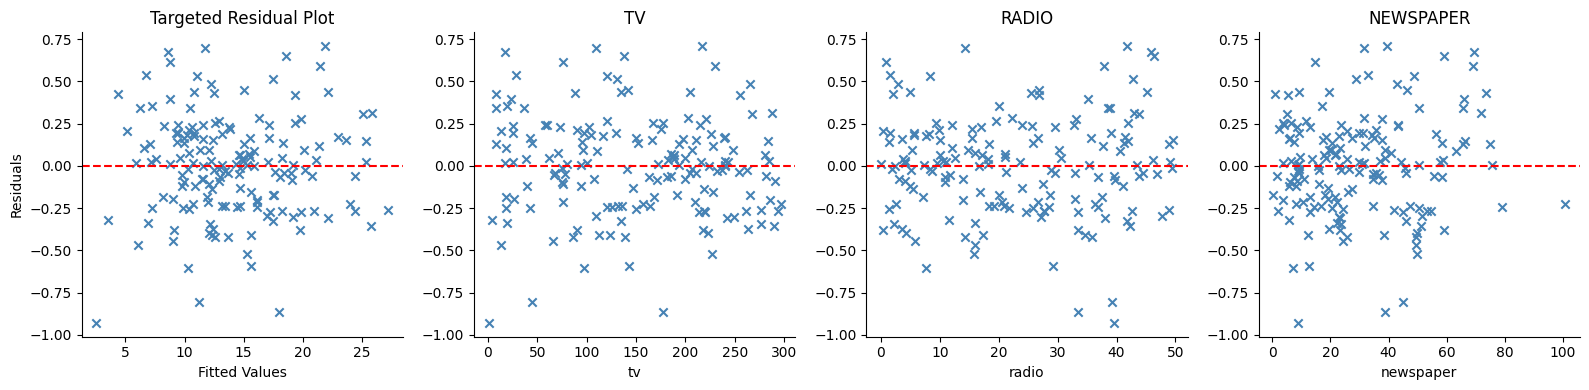

In [39]:
pred_targeted=targeted_pipe.predict(X_train)
resd_targeted=y_train-pred_targeted

fig, axes= plt.subplots(1,4,figsize=(16,4))
axes[0].scatter(pred_targeted,resd_targeted,marker='x',color='steelblue')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Targeted Residual Plot')
axes[0].axhline(y=0,c='r',ls='--')

for ax , col in zip(axes[1:],['tv','radio','newspaper']):
    ax.scatter(X_train[col],resd_targeted,marker='x',color='steelblue')
    ax.axhline(y=0,c='r',ls='--')
    ax.set_xlabel(col)
    ax.set_title(col.upper())

for ax in axes:
    ax.spines[['top','right']].set_visible(False)
plt.tight_layout()


In [40]:
resd_targeted.abs().sort_values(ascending=False).head(3)

130    0.929352
41     0.863564
1      0.805825
Name: sales, dtype: float64

In [41]:
X_tm=sm.add_constant(targeted_features(X_train))
m_targeted=sm.OLS(y_train,X_tm).fit(cov_type='HC3')
print(m_targeted.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                 1.303e+04
Date:                Wed, 07 Oct 2026   Prob (F-statistic):          5.58e-187
Time:                        18:11:53   Log-Likelihood:                -33.186
No. Observations:                 160   AIC:                             74.37
Df Residuals:                     156   BIC:                             86.67
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.5438      0.301     -1.808      0.0

x1 = 2.1221 with log(tv+1). To express it in tv units:

Per 1% increase in tv: 2.1221/100 = 0.0212 sales units
Per doubling of tv: 2.1221 × ln(2) = 1.471 sales units
x2 (radio, 0.0485) and x3 (tv·radio, 0.0010) are already in raw units
Not correlation but association 

In [42]:
infl = m_targeted.get_influence()
sf = infl.summary_frame()
print(sf[['cooks_d', 'hat_diag', 'student_resid']]
      .sort_values('cooks_d', ascending=False).head(8))

n, p = m_targeted.model.exog.shape
print('threshold 4/n:', 4/n)

      cooks_d  hat_diag  student_resid
130  0.520247  0.156039      -3.471718
2    0.093138  0.065010       2.348015
8    0.076616  0.119935       1.505674
1    0.070717  0.036750      -2.781052
155  0.050434  0.132126      -1.152345
91   0.043575  0.049310       1.847293
52   0.034986  0.024160       2.413963
22   0.032165  0.048624      -1.594431
threshold 4/n: 0.025


In [43]:
lm, lm_p, f, f_p = het_breuschpagan(m_targeted.resid, m_targeted.model.exog)
print(f"Breusch-Pagan p = {lm_p:.4f}")

Breusch-Pagan p = 0.0042


In [44]:
Z_new = sm.add_constant(targeted_features(X_test))
out = m_targeted.get_prediction(Z_new).summary_frame(alpha=0.05)
print(out[['mean', 'mean_ci_lower', 'mean_ci_upper',
           'obs_ci_lower', 'obs_ci_upper']].head())

        mean  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  16.957361      16.895303      17.019420     16.363112     17.551610
1  22.262770      22.159613      22.365927     21.662835     22.862705
2  21.149806      21.054902      21.244711     20.551235     21.748378
3   7.068711       6.854641       7.282782      6.440136      7.697287
4  24.048259      23.929577      24.166941     23.445460     24.651057


PI uses a pooled σ, so it's approximate given the BP result.

In [45]:
# #if standard scalar 
# mu, sd = scaler.mean_, scaler.scale_
# b=m_targeted.params
# b_raw = b[1:] / sd
# b0_raw = b[0] - np.sum(b[1:] * mu / sd)

In [46]:
test_pred=targeted_pipe.predict(X_test)
Report_MSE=mean_squared_error(y_test,test_pred)
Reprt_RMSE=root_mean_squared_error(y_test,test_pred)
Report_R2=r2_score(y_test,test_pred)

Report_MSE,Report_R2,Reprt_RMSE

(0.12959319709863606, 0.9958942192031401, 0.35999055140188896)

In [47]:
final_model=targeted_pipe.fit(X,y)
joblib.dump({
    'model': final_model,
    'columns': list(X.columns),
    'sklearn_version': sklearn.__version__,
}, 'ADV_SPEND_Prediction.joblib')

['ADV_SPEND_Prediction.joblib']

In [48]:
#function targeted feature needed this way . or put in separate importable file as module. or cloudpickle or write a trsnformer class